# Clay volume

Almost every interpretation starts with clay volume. It's rarely the goal in itself, but
porosity, water saturation, and net pay all depend on it, so it's worth getting right early.

The method is simple: take a log that responds to clay and scale it linearly between a
clean-formation reading and a shale reading. Gamma ray is the usual choice, since clays carry radioactive potassium and thorium. Shales read high, clean sands read low.

## The clay index

Both indicators the workflow uses are deterministic, evaluated sample by sample. The gamma-ray one,
plotted in orange below, scales the log linearly between a clean and a shale reading,

$$V_{cl}^{GR} = \frac{GR - GR_{min}}{GR_{max} - GR_{min}}$$

clipped to $[0, 1]$, with $GR_{min}$ the clean-sand reading and $GR_{max}$ the shale reading. The
neutron-density one (blue) is a closed-form expression in the two logs against three fixed
end-points: two clean-matrix points $(\rho_1, \phi_{N1})$ and $(\rho_2, \phi_{N2})$ that set the
clean line, and a wet-clay point $(\rho_{cl}, \phi_{N,cl})$,

$$V_{cl}^{ND} = \frac{(\rho_2 - \rho_1)(\phi_N - \phi_{N1}) - (\rho_b - \rho_1)(\phi_{N2} - \phi_{N1})}
{(\rho_2 - \rho_1)(\phi_{N,cl} - \phi_{N1}) - (\rho_{cl} - \rho_1)(\phi_{N2} - \phi_{N1})}$$

also clipped to $[0, 1]$. For the sandstone matrix used here the end-points are fixed constants,
density in g/cc and neutron in v/v:

| point | $\rho$ | $\phi_N$ |
|---|---|---|
| clean matrix, zero porosity | 2.65 | $-0.02$ |
| clean matrix, ~40 p.u. water | 1.99 | 0.38 |
| wet clay | 2.62 | 0.38 |

The clean line is keyed to the matrix (limestone and dolomite carry their own pair); the clay point
is held fixed. This index needs no clean and shale gamma-ray picks and is not fooled by uranium-rich clean zones. By default `calculate_vcl` combines the available indices conservatively, taking their per-depth minimum; the workflow switches to `combine="auto"` when neutron-density is available, which keeps the neutron-density value where it is reliable and uses gamma ray only where gas crossover spoils the neutron or the neutron is missing.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "src" / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))
WELL = REPO / "src" / "petrophys" / "datasets" / "geolink" / "30_6-5.las"

from petrophys.io import read_las
from petrophys.interpretation.clay_volume import calculate_vcl
well = read_las(WELL)
vcl = calculate_vcl(well)
vcl.vcl_gr[:5].round(3)            # the gamma-ray estimate, sample by sample

array([0.088, 0.088, 0.088, 0.098, 0.1  ])

`calculate_vcl` runs three estimates (gamma ray, SP, and neutron-density) because the
gamma-ray version on its own has two failure modes that pull in opposite directions. It
over-reads clay in sands containing feldspar, mica, or heavy minerals, which are radioactive but
not clay. And it under-reads clay that is low in radioactive elements; a kaolinite-rich shale can
look almost clean on gamma ray.

Neutron-density responds to the clay mineral itself rather than its radioactivity (bound water
raises the neutron, grain density shifts the density), so it usually catches what gamma ray
misses. Plotting them together shows where they part company:

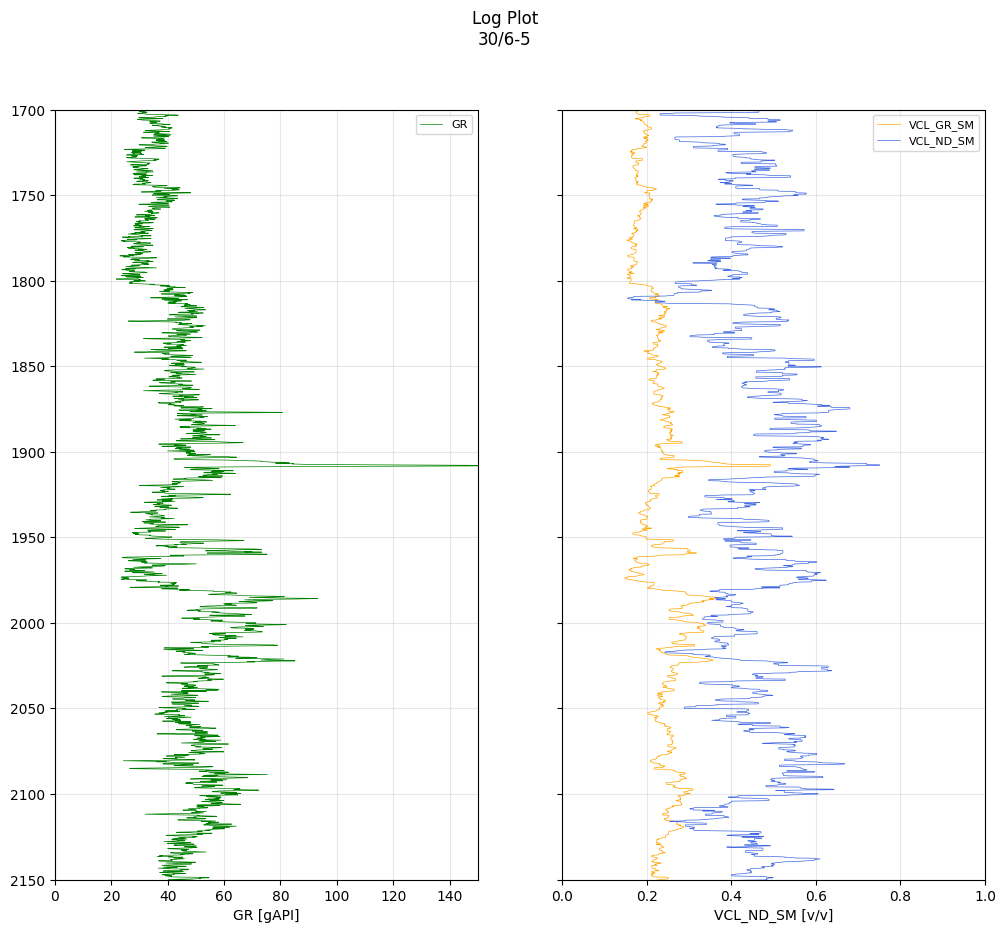

In [2]:
import pandas as pd
from petrophys.interpretation.clay_volume.vcl_module import VclModule
from petrophys.visualization import create_log_plot
VclModule(matrix="sandstone", combine="auto").add_to_well(well)   # writes VCL_GR, VCL_ND, VCL
# the neutron-density clay estimate is noisy sample-to-sample (it amplifies log
# noise), so smooth both with a short rolling median before comparing them
for c in ["VCL_GR", "VCL_ND"]:
    s = pd.Series(well.get(c).data).rolling(11, center=True, min_periods=3).median().to_numpy()
    well.add_curve(c + "_SM", s, "v/v", c + " smoothed")
create_log_plot(well, depth_range=(1700, 2150), curves=[
    {"track": 0, "name": "GR", "color": "green", "xlim": (0, 150)},
    {"track": 1, "name": "VCL_GR_SM", "color": "orange", "xlim": (0, 1)},
    {"track": 1, "name": "VCL_ND_SM", "color": "royalblue", "xlim": (0, 1)},
]);

Where the gamma-ray (orange) and neutron-density (blue) estimates separate, one of them is being misled, by non-radioactive clay the gamma ray misses, or by radioactive minerals that are not clay. The workflow's combined VCL follows the neutron-density
estimate where it's reliable and falls back to gamma ray where gas affects the neutron, so you
don't set that by hand. It's still worth knowing which curve drives the result at a given depth.
The disagreements are where interpretations most often go wrong, and they're the first thing worth
a second look.